# アルゴリズム論Ⅱ 

## 第5回：最急降下法

前回の「第4回：ガウスの消去法」では、連立一次方程式 $A \mathbf{x} = \mathbf{b}$ を解くための直接解法を学びました。ガウスの消去法は厳密解を有限ステップで求める強力な手法ですが、未知数の数 $n$ に対して計算量が $O(n^3)$ で増大するため、未知数が数万〜数億に達する現代の機械学習や深層学習、超大規模データ解析においては、行列の直接分解をそのまま適用することが計算量・メモリ量の両面で困難になります。

そこで登場するのが、関数の「傾き（勾配：Gradient）」を手がかりにして、反復的に目的関数を最小化する **「最急降下法（Steepest Descent, Gradient Descent）」** です。

最急降下法は、現代の**機械学習（線形回帰、ロジスティック回帰、ニューラルネットワーク・深層学習）**や、**適応信号処理（アクティブノイズキャンセル、通信の等化器）**の学習アルゴリズムとして世界中で最も広く使われている最適化手法です。

その発想は極めてシンプルですが、コンピュータ上で実際に動作させる際には、**学習率（ステップサイズ）の選び方**によってアルゴリズムの運命が激変します：
- 学習率が大きすぎると、解を飛び越えて**激しく振動・発散（オーバーフロー）**する
- 学習率が小さすぎると、計算に膨大な時間がかかり実質的に**停滞**する
- パラメータによってスケールが異なる「細長い谷（峡谷）」では、**激しいジグザグ現象**に陥り前進できなくなる

以下では、次のような重要ポイントを説明します：
1. **勾配（Gradient）の幾何学的意味と最急降下の数理原理**
2. **学習率 $\eta$ がもたらす劇的な挙動変化（収束・振動・爆発）**
3. **実社会応用：回帰分析 ＆ 信号処理での適応ノイズキャンセル**


---
## 1. 最急降下法の原理と数理的仕組み

### 勾配（Gradient）とは何か？
多変数関数 $f(\mathbf{x}) = f(x_1, x_2, \dots, x_d)$ において、各変数による偏微分を並べたベクトルを **勾配（Gradient）** と呼び、記号 $\nabla f(\mathbf{x})$ で表します：

$$
\nabla f(\mathbf{x}) = \begin{bmatrix}
\frac{\partial f}{\partial x_1} \\
\frac{\partial f}{\partial x_2} \\
\vdots \\
\frac{\partial f}{\partial x_d}
\end{bmatrix}
$$

> **📐 勾配の重要な幾何学的性質**  
> 勾配ベクトル $\nabla f(\mathbf{x})$ は、現在地 $\mathbf{x}$ において **「関数値 $f(\mathbf{x})$ が最も急激に増加する方向（最急上昇方向）」** を指しており、その大きさ $\|\nabla f(\mathbf{x})\|$ はその方向への傾きの大きさを表します。

したがって、関数値 $f(\mathbf{x})$ を最も急速に減少（最小化）させたいならば、**勾配の逆方向 $-\nabla f(\mathbf{x})$** に向かって進めばよいことになります。これが **「最急降下法（Method of Steepest Descent）」** の基本思想です。

---

### 最急降下法の更新式
現在地を $\mathbf{x}_k$、次のステップの探索点を $\mathbf{x}_{k+1}$ とすると、更新規則は次式で与えられます：

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)
$$

ここで、正のスカラ定数 $\eta > 0$ は **学習率（Learning Rate）** または **ステップサイズ（Step Size）** と呼ばれ、「1回の反復で傾きの方向にどれだけ進むか」を決定する最重要ハイパーパラメータです。
（$\eta$ はギリシャ文字で、イータと読みます。）

1変数の関数 $f(x)$ の場合は、通常の微分 $f'(x)$ を用いて以下のように表されます：

$$
x_{k+1} = x_k - \eta f'(x_k)
$$

- $f'(x_k) > 0$（右上がり）のとき：$-\eta f'(x_k) < 0$ となり、$x$ は左（減少する方向）へ進む。
- $f'(x_k) < 0$（右下がり）のとき：$-\eta f'(x_k) > 0$ となり、$x$ は右（減少する方向）へ進む。
- $f'(x_k) = 0$（傾きゼロ）のとき：更新量は $0$ となり、その場に留まる（停留点・極値に到達）。


---
## 2. ナイーブな基本実装と動作検証（1変数関数の最小化）

まずは、手計算でも厳密に追えるシンプルな二次関数を用いて、最急降下法の素朴（ナイーブ）なアルゴリズムを実装し、その動作を検証します。

### 検証モデル
目的関数として次の二次関数を考えます：
$$ f(x) = (x - 3)^2 + 2 $$
導関数（微分）は：
$$ f'(x) = 2(x - 3) $$

解析的な最適解は $x^* = 3$（このとき最小値 $f(x^*) = 2$、勾配 $f'(x^*) = 0$）です。  
初期値を $x_0 = -2.0$、学習率を $\eta = 0.15$ に設定して降下の様子を追跡します。


Step (k) |          x_k |       f(x_k) |      f'(x_k) |   |x_k - x*|
-----------------------------------------------------------------
       0 |    -2.000000 |    27.000000 |   -10.000000 |   5.0000e+00
       1 |    -0.500000 |    14.250000 |    -7.000000 |   3.5000e+00
       2 |     0.550000 |     8.002500 |    -4.900000 |   2.4500e+00
       3 |     1.285000 |     4.941225 |    -3.430000 |   1.7150e+00
       4 |     1.799500 |     3.441200 |    -2.401000 |   1.2005e+00
       5 |     2.159650 |     2.706188 |    -1.680700 |   8.4035e-01
       6 |     2.411755 |     2.346032 |    -1.176490 |   5.8825e-01
       7 |     2.588229 |     2.169556 |    -0.823543 |   4.1177e-01
       8 |     2.711760 |     2.083082 |    -0.576480 |   2.8824e-01
       9 |     2.798232 |     2.040710 |    -0.403536 |   2.0177e-01
...
最終到達点 (k=20): x = 2.996010, 誤差 = 3.9896e-03


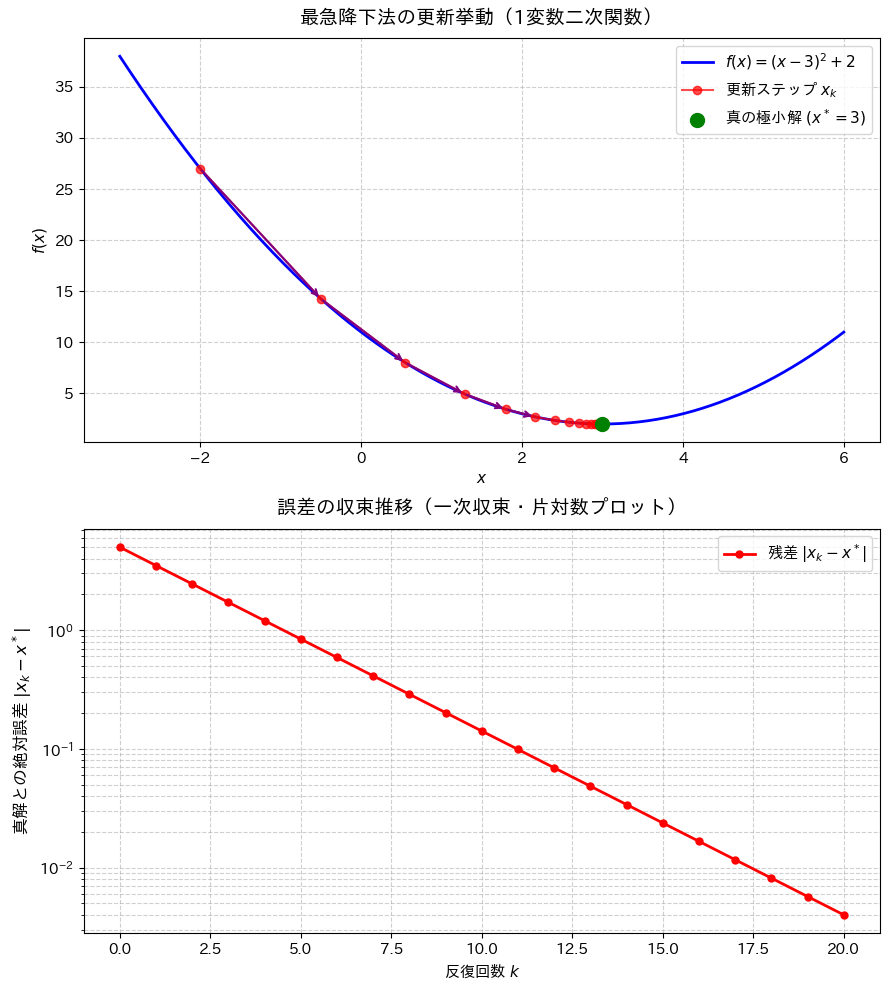

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib
# 1. 目的関数とその微分の定義
def f(x):
    return (x - 3.0)**2 + 2.0
def df(x):
    return 2.0 * (x - 3.0)
# 最急降下法（1変数）の実装
def gradient_descent_1d(f, df, x0, eta, max_iter=25, tol=1e-6):
    x = x0
    history = [(0, x, f(x), df(x))]
    for k in range(1, max_iter + 1):
        grad = df(x)
        x_new = x - eta * grad
        history.append((k, x_new, f(x_new), df(x_new)))
        if abs(x_new - x) < tol or abs(grad) < tol:
            break
        x = x_new
    return x, history
# パラメータ設定
x0 = -2.0      # 初期値
eta = 0.15     # 学習率
x_star = 3.0   # 解析的最適解
x_opt, history = gradient_descent_1d(f, df, x0=x0, eta=eta, max_iter=20)
print("{:>8} | {:>12} | {:>12} | {:>12} | {:>12}".format('Step (k)', 'x_k', 'f(x_k)', "f'(x_k)", '|x_k - x*|'))
print("-" * 65)
for step, x_k, fx_k, dfx_k in history[:10]:
    err = abs(x_k - x_star)
    print(f"{step:8d} | {x_k:12.6f} | {fx_k:12.6f} | {dfx_k:12.6f} | {err:12.4e}")
print("...")
print(f"最終到達点 (k={history[-1][0]}): x = {x_opt:.6f}, 誤差 = {abs(x_opt - x_star):.4e}")
# 可視化
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))
# 左図：関数の形状と降下の軌跡
x_vals = np.linspace(-3, 6, 400)
ax1.plot(x_vals, f(x_vals), 'b-', label=r'$f(x) = (x-3)^2 + 2$', linewidth=2)
x_hist = [h[1] for h in history]
f_hist = [h[2] for h in history]
ax1.plot(x_hist, f_hist, 'ro-', markersize=6, alpha=0.7, label=r'更新ステップ $x_k$')
ax1.scatter([x_star], [f(x_star)], color='green', s=100, zorder=5, label=r'真の極小解 $(x^*=3)$')
# 最初の数ステップの移動を矢印で強調
for i in range(min(5, len(x_hist) - 1)):
    ax1.annotate('', xy=(x_hist[i+1], f_hist[i+1]), xytext=(x_hist[i], f_hist[i]),
                 arrowprops=dict(arrowstyle="->", color="purple", lw=1.5))
ax1.set_title('最急降下法の更新挙動（1変数二次関数）', fontsize=14, pad=10)
ax1.tick_params(labelsize=11)
ax1.set_xlabel('$x$', fontsize=11)
ax1.set_ylabel('$f(x)$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=11)
# 右図：誤差の片対数プロット（一次収束の確認）
steps = [h[0] for h in history]
errors = [abs(h[1] - x_star) for h in history]
ax2.semilogy(steps, errors, 'r-o', lw=2, markersize=5, label=r'残差 $|x_k - x^*|$')
ax2.set_title('誤差の収束推移（一次収束・片対数プロット）', fontsize=14, pad=10)
ax2.tick_params(labelsize=11)
ax2.set_xlabel('反復回数 $k$', fontsize=11)
ax2.set_ylabel('真解との絶対誤差 $|x_k - x^*|$', fontsize=12)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)
ax2.legend(fontsize=11)
plt.tight_layout()
plt.show()


---
## 3. 学習率が大きすぎる場合の振動・発散（オーバーフロー）

最急降下法において、初心者が最も頻繁に遭遇する致命的な落とし穴が **「学習率 $\eta$ の過大設定による発散」** です。

### 数理的メカニズム：なぜ発散するのか？
二次関数 $f(x) = \frac{1}{2} a x^2$（$a > 0$、極小解 $x^* = 0$）を考えます。導関数は $f'(x) = a x$ です。  
このとき、最急降下法の漸化式は次のように書けます：

$$
x_{k+1} = x_k - \eta (a x_k) = (1 - \eta a) x_k
$$

これを繰り返すと、一般項は初項 $x_0$ を用いて直ちに求まります：
$$
x_k = (1 - \eta a)^k x_0
$$

公比 $R = 1 - \eta a$ の絶対値 $|R|$ によって、収束の挙動は完全に決定づけられます：
1. **$0 < 1 - \eta a < 1$（すなわち $0 < \eta < \frac{1}{a}$）**：  
   符号を変えずに単調に $0$ へ収束する。
2. **$-1 < 1 - \eta a < 0$（すなわち $\frac{1}{a} < \eta < \frac{2}{a}$）**：  
   極小値 $0$ を挟んで左右に振動しながら、徐々に振幅が小さくなって収束する（減衰振動）。
3. **$1 - \eta a = -1$（すなわち $\eta = \frac{2}{a}$）**：  
   臨界限界。$x_k = (-1)^k x_0$ となり、$x_0$ と $-x_0$ の間を永遠に行き来し、全く収束しない（振動し続ける）。
4. **$1 - \eta a < -1$（すなわち $\eta > \frac{2}{a}$）**：  
   **発散（Explosion）！** ステップごとに振幅が $|1 - \eta a| > 1$ 倍に拡大し、指数関数的に解が彼方へ吹き飛びます。

コンピュータ上では、数ステップで浮動小数点数の表現限界（約 $1.8 \times 10^{308}$）を突破し、`inf`（無限大）や `nan`（非数）となってプログラムが異常停止します。


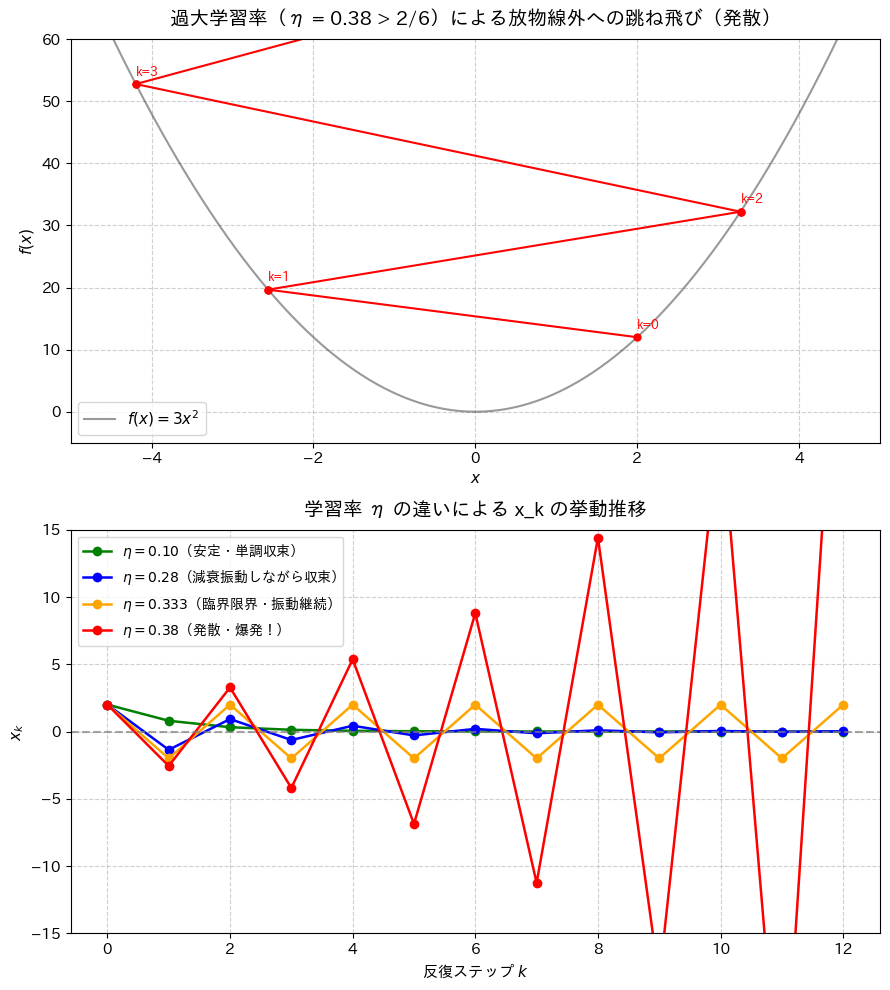

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib
# 目的関数 f(x) = 3 x^2, f'(x) = 6 x
# 二次微分 f''(x) = 6 なので、臨界安定限界は eta_crit = 2 / 6 = 0.333333...
def f(x):
    return 3.0 * x**2
def df(x):
    return 6.0 * x
def run_gd_safe(x0, eta, max_steps=12):
    traj = [x0]
    x = x0
    for k in range(max_steps):
        try:
            grad = df(x)
            x_new = x - eta * grad
            if math.isnan(x_new) or math.isinf(x_new) or abs(x_new) > 1e10:
                print(f"⚠️ 学習率 eta = {eta:.4f}: ステップ {k+1} で発散検知！(|x| > 10^10)")
                break
            x = x_new
            traj.append(x)
        except OverflowError:
            print(f"⚠️ 学習率 eta = {eta:.4f}: オーバーフロー例外発生！")
            break
    return traj
x0 = 2.0
etas = [0.10, 0.28, 0.3333, 0.38]
labels = [
    r'$\eta = 0.10$（安定・単調収束）',
    r'$\eta = 0.28$（減衰振動しながら収束）',
    r'$\eta = 0.333$（臨界限界・振動継続）',
    r'$\eta = 0.38$（発散・爆発！）'
]
colors = ['green', 'blue', 'orange', 'red']
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))
# 左図：放物線上の飛び跳ねの可視化 (eta = 0.38 の発散 vs 放物線)
x_curve = np.linspace(-5, 5, 400)
ax1.plot(x_curve, f(x_curve), 'k-', alpha=0.4, label=r'$f(x) = 3x^2$')
traj_div = run_gd_safe(x0, 0.38, max_steps=5)
for i in range(len(traj_div)-1):
    x_cur, x_next = traj_div[i], traj_div[i+1]
    ax1.plot([x_cur, x_next], [f(x_cur), f(x_next)], 'r-o', lw=1.5, markersize=5)
    ax1.annotate(f"k={i}", xy=(x_cur, f(x_cur)), textcoords="offset points", xytext=(0, 6),
                 fontsize=9, color='red', weight='bold')
ax1.set_ylim(-5, 60)
ax1.set_xlim(-5, 5)
ax1.set_title('過大学習率（η = 0.38 > 2/6）による放物線外への跳ね飛び（発散）', fontsize=14, pad=10)
ax1.tick_params(labelsize=11)
ax1.set_xlabel('$x$', fontsize=11)
ax1.set_ylabel('$f(x)$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=11)
# 右図：反復ステップごとの x_k の推移
for eta, label, color in zip(etas, labels, colors):
    traj = run_gd_safe(x0, eta, max_steps=12)
    ax2.plot(range(len(traj)), traj, marker='o', lw=1.8, color=color, label=label)
ax2.axhline(0, color='gray', linestyle='--', alpha=0.7)
ax2.set_title('学習率 η の違いによる x_k の挙動推移', fontsize=14, pad=10)
ax2.tick_params(labelsize=11)
ax2.set_xlabel('反復ステップ $k$', fontsize=11)
ax2.set_ylabel('$x_k$', fontsize=11)
ax2.set_ylim(-15, 15)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=10, loc='upper left')
plt.tight_layout()
plt.show()


---
## 4. 学習率の違いによる計算プロセスの変化

アルゴリズムの設計・運用において最も重要な「学習率 $\eta$ の選択」が最適化計算の経過に与える影響を比較します。

### 実験条件
- 目的関数：$f(x, y) = 0.5 x^2 + 2.0 y^2$
- 初期点：$(x_0, y_0) = (4.0, 3.0)$、大域的最小値：$(0, 0)$
- 勾配ベクトル：$\nabla f = [x, 4y]^T$ （$y$ 軸の最大曲率は $4$、臨界発散境界は $\eta_{\text{crit}} = \frac{2}{4} = 0.5$）
- 評価する学習率：
  - $\eta = 0.03$（過小：歩幅が小さすぎて極めて遅い）
  - $\eta = 0.12$（安全圏：滑らかに安定収束）
  - $\eta = 0.25$（最適値：最も素早く最小値へ収束）
  - $\eta = 0.45$（過大：$y$ 軸で激しい減衰振動・オーバーシュート）
  - $\eta = 0.51$（臨界超え：$2/4=0.5$ を超過し、爆発的発散）


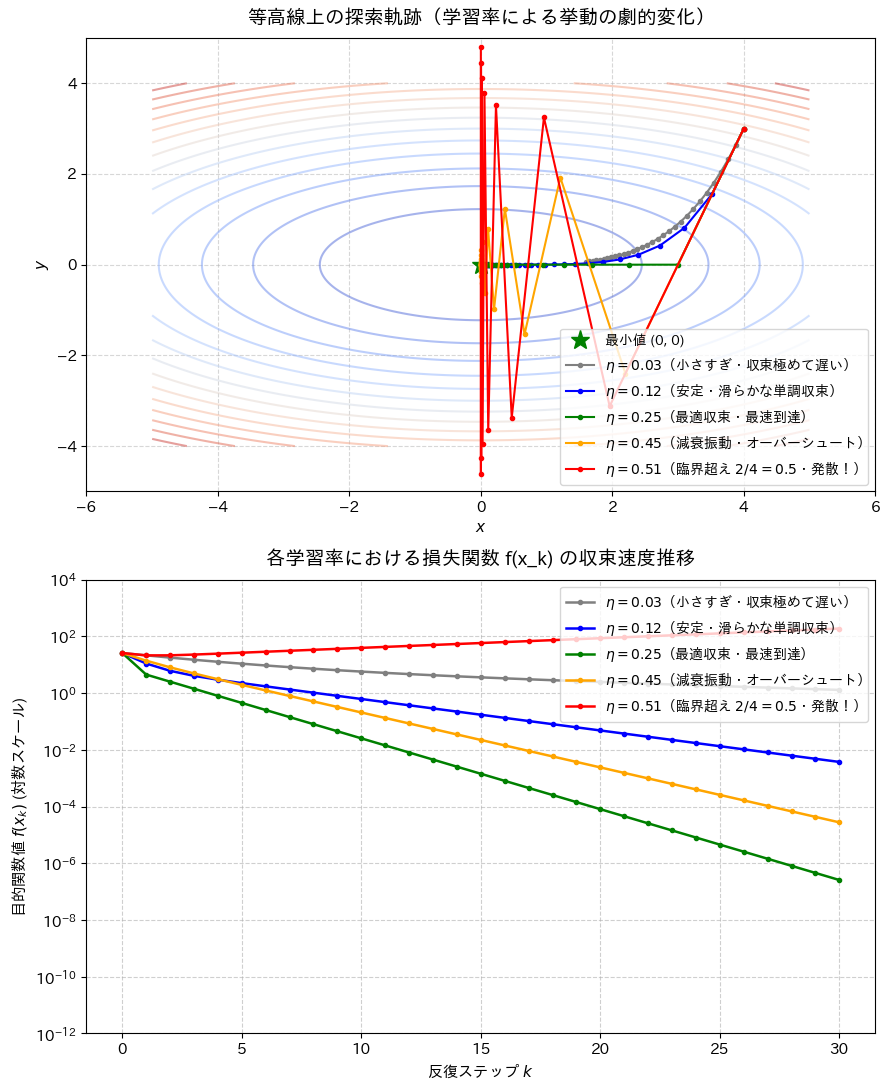

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib
# 目的関数: f(x, y) = 0.5 * x^2 + 2.0 * y^2, 最小値 (0, 0), f* = 0
def f_quad(x, y):
    return 0.5 * x**2 + 2.0 * y**2
def grad_quad(p):
    return np.array([1.0 * p[0], 4.0 * p[1]])
def run_gd_experiment(p0, eta, steps=30):
    traj = [p0.copy()]
    losses = [f_quad(p0[0], p0[1])]
    p = p0.copy()
    for _ in range(steps):
        g = grad_quad(p)
        p = p - eta * g
        traj.append(p.copy())
        losses.append(f_quad(p[0], p[1]))
    return np.array(traj), np.array(losses)
p0 = np.array([4.0, 3.0])
steps = 30
test_etas = [0.03, 0.12, 0.25, 0.45, 0.51]
labels = [
    r'$\eta = 0.03$（小さすぎ・収束極めて遅い）',
    r'$\eta = 0.12$（安定・滑らかな単調収束）',
    r'$\eta = 0.25$（最適収束・最速到達）',
    r'$\eta = 0.45$（減衰振動・オーバーシュート）',
    r'$\eta = 0.51$（臨界超え $2/4=0.5$・発散！）'
]
colors = ['gray', 'blue', 'green', 'orange', 'red']
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 11))
# 左図：等高線と各軌跡の比較
x = np.linspace(-5, 5, 300)
y = np.linspace(-4, 4, 300)
X, Y = np.meshgrid(x, y)
Z = f_quad(X, Y)
ax1.contour(X, Y, Z, levels=15, cmap='coolwarm', alpha=0.5)
ax1.plot(0, 0, 'g*', markersize=14, label='最小値 (0, 0)')
for eta, label, color in zip(test_etas, labels, colors):
    traj, _ = run_gd_experiment(p0, eta, steps=12 if eta > 0.5 else steps)
    ax1.plot(traj[:, 0], traj[:, 1], marker='o', lw=1.5, markersize=3, color=color, label=label)
ax1.set_xlim(-6, 6)
ax1.set_ylim(-5, 5)
ax1.set_title('等高線上の探索軌跡（学習率による挙動の劇的変化）', fontsize=14, pad=10)
ax1.tick_params(labelsize=11)
ax1.set_xlabel('$x$', fontsize=11)
ax1.set_ylabel('$y$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10, loc='lower right')
# 右図：損失値 f(x_k) の片対数プロット
for eta, label, color in zip(test_etas, labels, colors):
    traj, losses = run_gd_experiment(p0, eta, steps=steps)
    # 発散値が巨大になりすぎないようクリップ
    losses_plot = np.clip(losses, 1e-16, 1e8)
    ax2.semilogy(range(len(losses_plot)), losses_plot, marker='o', lw=1.8, markersize=3, color=color, label=label)
ax2.set_title('各学習率における損失関数 f(x_k) の収束速度推移', fontsize=14, pad=10)
ax2.tick_params(labelsize=11)
ax2.set_xlabel('反復ステップ $k$', fontsize=11)
ax2.set_ylabel('目的関数値 $f(x_k)$ (対数スケール)', fontsize=11)
ax2.set_ylim(1e-12, 1e4)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)
ax2.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()


---
## 5. 最急降下法を用いる実例

### 単回帰・重回帰モデルの最小二乗学習

#### 背景：なぜビッグデータでは正規方程式ではなく勾配降下法を使うのか？
$N$ 個のデータ点 $(x_1, y_1), \dots, (x_N, y_N)$ に対して、直線モデル $\hat{y} = w x + b$ をフィットさせる問題を考えます。
目的関数は、予測値と正解値の差の二乗平均である **平均二乗誤差（MSE: Mean Squared Error）損失** です：

$$
J(w, b) = \frac{1}{2N} \sum_{i=1}^N \bigl( (w x_i + b) - y_i \bigr)^2
$$

各パラメータに関する偏微分（勾配）は次式で直ちに求まります：
$$
\begin{aligned}
\frac{\partial J}{\partial w} &= \frac{1}{N} \sum_{i=1}^N \bigl( (w x_i + b) - y_i \bigr) x_i \\
\frac{\partial J}{\partial b} &= \frac{1}{N} \sum_{i=1}^N \bigl( (w x_i + b) - y_i \bigr)
\end{aligned}
$$

第4回で学んだように、線形代数の「正規方程式」を用いれば $\boldsymbol{\theta}^* = (X^T X)^{-1} X^T \mathbf{y}$ として厳密解が一発で求まります。  
しかし、特徴量の次元 $d$ が数万〜数十万（テキストのBag-of-Wordsや画像特徴など）になると、行列積 $X^T X$ や逆行列計算に **$O(d^3)$ の天文学的計算量** と膨大なメモリが必要になり、計算不能に陥ります。

一方、最急降下法を用いれば、**1ステップあたり $O(Nd)$ の軽い計算量とごくわずかなメモリ** だけでパラメータ $(w, b)$ を最適解へと着実に収束させることができます。


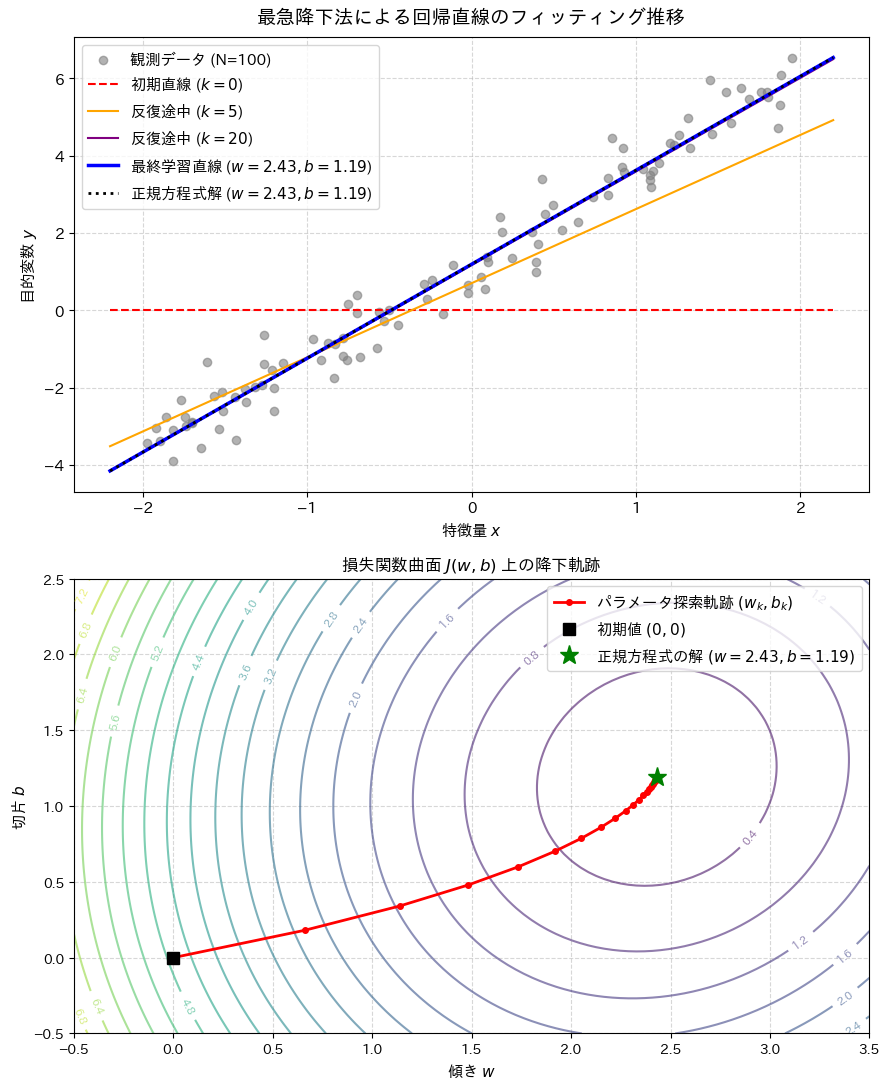

🎯 最適化結果の比較:
   最急降下法 (60ステップ): w = 2.431033, b = 1.191121, MSE損失 = 0.145185
   正規方程式 (解析的厳密解): w = 2.431034, b = 1.191126, MSE損失 = 0.145185
   真の生成パラメータ       : w = 2.500000, b = 1.200000


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. ダミーデータの生成（真のパラメータ: w_true = 2.5, b_true = 1.2）
np.random.seed(42)
N = 100
x_data = np.random.uniform(-2.0, 2.0, N)
noise = np.random.normal(0.0, 0.6, N)
y_data = 2.5 * x_data + 1.2 + noise

# 2. 勾配降下法によるパラメータ探索
def compute_loss(w, b, x, y):
    return np.mean((w * x + b - y)**2) / 2.0
def compute_grads(w, b, x, y):
    error = (w * x + b) - y
    grad_w = np.mean(error * x)
    grad_b = np.mean(error)
    return grad_w, grad_b
# 勾配降下法の実行
w, b = 0.0, 0.0  # 初期値
eta = 0.2        # 学習率
iterations = 60
history_w = [w]
history_b = [b]
history_loss = [compute_loss(w, b, x_data, y_data)]
for it in range(iterations):
    gw, gb = compute_grads(w, b, x_data, y_data)
    w = w - eta * gw
    b = b - eta * gb
    history_w.append(w)
    history_b.append(b)
    history_loss.append(compute_loss(w, b, x_data, y_data))

# 3. 解析解（正規方程式による厳密解）
X_design = np.column_stack([x_data, np.ones(N)])
theta_normal = np.linalg.inv(X_design.T @ X_design) @ (X_design.T @ y_data)
w_norm, b_norm = theta_normal[0], theta_normal[1]

# 4. 可視化
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 11))
# 左図：回帰直線の更新過程
ax1.scatter(x_data, y_data, color='gray', alpha=0.6, label='観測データ (N=100)')
x_line = np.linspace(-2.2, 2.2, 100)
ax1.plot(x_line, history_w[0] * x_line + history_b[0], 'r--', lw=1.5, label='初期直線 ($k=0$)')
ax1.plot(x_line, history_w[5] * x_line + history_b[5], 'orange', lw=1.5, label='反復途中 ($k=5$)')
ax1.plot(x_line, history_w[20] * x_line + history_b[20], 'purple', lw=1.5, label='反復途中 ($k=20$)')
ax1.plot(x_line, w * x_line + b, 'b-', lw=2.5, label=f'最終学習直線 ($w={w:.2f}, b={b:.2f}$)')
ax1.plot(x_line, w_norm * x_line + b_norm, 'k:', lw=2, label=f'正規方程式解 ($w={w_norm:.2f}, b={b_norm:.2f}$)')
ax1.set_title('最急降下法による回帰直線のフィッティング推移', fontsize=14, pad=10)
ax1.tick_params(labelsize=11)
ax1.set_xlabel('特徴量 $x$', fontsize=11)
ax1.set_ylabel('目的変数 $y$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=11)
# 右図：損失関数 J(w, b) の等高線とパラメータ更新の軌跡
w_vals = np.linspace(-0.5, 3.5, 100)
b_vals = np.linspace(-0.5, 2.5, 100)
W, B = np.meshgrid(w_vals, b_vals)
Loss_surf = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Loss_surf[i, j] = compute_loss(W[i, j], B[i, j], x_data, y_data)
contours = ax2.contour(W, B, Loss_surf, levels=20, cmap='viridis', alpha=0.6)
ax2.clabel(contours, inline=True, fontsize=8)
ax2.plot(history_w, history_b, 'r-o', lw=2.0, markersize=4, label='パラメータ探索軌跡 $(w_k, b_k)$')
ax2.plot(history_w[0], history_b[0], 'ks', markersize=8, label='初期値 $(0, 0)$')
ax2.plot(w_norm, b_norm, 'g*', markersize=14, label=f'正規方程式の解 $(w={w_norm:.2f}, b={b_norm:.2f})$')
ax2.set_title('損失関数曲面 $J(w, b)$ 上の降下軌跡', fontsize=12)
ax2.set_xlabel('傾き $w$', fontsize=11)
ax2.set_ylabel('切片 $b$', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)
plt.tight_layout()
plt.show()
print(f"🎯 最適化結果の比較:")
print(f"   最急降下法 ({iterations}ステップ): w = {w:.6f}, b = {b:.6f}, MSE損失 = {history_loss[-1]:.6f}")
print(f"   正規方程式 (解析的厳密解): w = {w_norm:.6f}, b = {b_norm:.6f}, MSE損失 = {compute_loss(w_norm, b_norm, x_data, y_data):.6f}")
print(f"   真の生成パラメータ       : w = 2.500000, b = 1.200000")


---

### 参考：信号処理・適応フィルタへの応用
ノイズキャンセリングヘッドホンやスマートフォンの通話ノイズ除去、通信の適応等化器（Echo Canceller）では、**「未知の伝達経路を通って混入してくる雑音を、リアルタイムに同定して逆位相で打ち消す」** 技術が用いられます。

これを実現する世界標準のアルゴリズムが、WidrowとHoffが提案した **LMS（Least Mean Squares）アルゴリズム** です。LMSは、最急降下法をストリーミング信号処理向けに変更したものです。
